# Semana 1 — Datos marcianos y mapa de pendientes
### NASA Space Apps Challenge · Marswalk · Cráter Jezero

**Objetivo de la libreta:** cargar un Modelo Digital de Elevación (DEM) de Marte,
calcular la pendiente en grados de forma correcta (convirtiendo el espaciado de
píxel a metros) y exportar un mapa de pendientes.

**Mini entregable A:** script reproducible + figura PNG + GeoTIFF del recorte.

> Esta libreta está pensada para ejecutarse de principio a fin en Google Colab.
> Si aún no tienes el DEM real de Jezero, la libreta **genera un DEM sintético
> de respaldo** para que puedas practicar todo el flujo.

## 2. Anatomía de un ráster con `rasterio`

Al abrir un ráster con `rasterio.open()` obtienes un objeto con metadatos clave:

- **`src.crs`**: Sistema de Referencia de Coordenadas. Puede ser **geográfico**
  (grados, típico de MOLA/HiRISE) o **proyectado** (metros).
- **`src.transform`**: transformación afín que mapea (col, fila) → (x, y).
  - `src.transform.a` = tamaño de píxel en X (unidades del CRS)
  - `src.transform.e` = tamaño de píxel en Y (usualmente negativo)
- **`src.nodata`**: valor que marca celdas sin datos (p. ej. `-9999`).
- **`src.bounds`**: extensión geográfica del ráster.

### La trampa más común

Si el CRS está en **grados**, `transform.a` y `transform.e` también están en
grados. Si usas esos valores directamente en `np.gradient`, ¡las pendientes
saldrán absurdas! **Debes convertir el espaciado a metros antes de calcular
el gradiente.**

In [2]:
!pip install -q rasterio geopandas matplotlib numpy scipy
print("Dependencias instaladas")

Dependencias instaladas


In [3]:
# Opcional: montar Google Drive para guardar resultados de forma persistente
from google.colab import drive
drive.mount('/content/drive')

# Ejemplo de carpeta de trabajo en Drive
import os
WORKDIR = "/content/drive/MyDrive/marswalk"
os.makedirs(WORKDIR, exist_ok=True)
print(f"Carpeta de trabajo: {WORKDIR}")

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/marswalk


## 1. ¿Qué es un DEM?

Un **Modelo Digital de Elevación (DEM)** es una matriz regular de valores
de elevación (z) sobre una cuadrícula geográfica. Cada celda representa una
porción del terreno, y la resolución (tamaño de píxel) define el nivel de detalle.

### Productos clave para Marte

| Producto | Instrumento | Resolución | Uso típico |
|---|---|---|---|
| **MOLA** | Mars Orbiter Laser Altimeter | ~463 m/píxel | Contexto global, planificación de gran escala |
| **CTX DEM** | Context Camera | ~20 m/píxel | Excelente compromiso para el cráter Jezero |
| **HiRISE DTM** | High Resolution Imaging Science Experiment | 0.25–1 m/píxel | Análisis detallado de zonas de aterrizaje |

### ¿Cuál usar en el prototipo?

- **Empezar con CTX (20 m/píxel)** cubre todo Jezero y es manejable.
- **HiRISE (0.25–1 m/píxel)** para validaciones locales de alta precisión.
- **MOLA (~463 m/píxel)** si necesitas contexto regional.

> Un DEM de HiRISE completo puede pesar cientos de MB. En Colab, usa
> **recortes** (`rasterio.windows.Window`) o submuestreo (`read(out_shape=...)`).

## 3. Conversión de grados a metros en Marte (En detalle)

Al trabajar con datos geoespaciales no proyectados (cuyas coordenadas están en grados de latitud y longitud, como WGS84 o sistemas equivalentes marcianos), es crucial convertir estas unidades angulares a unidades métricas lineales para calcular correctamente distancias, áreas y pendientes.

### 3.1. Fórmulas base (Aproximación esférica)
Para Marte, solemos usar una aproximación esférica (aunque es un elipsoide, para cálculos básicos a nivel local es una excelente aproximación):
- **Radio medio de Marte (R):** ~3389.5 km
- **Circunferencia polar/ecuatorial media:** $2 \cdot \pi \cdot R \approx 21\,296$ km

Dado que hay 360 grados en un círculo completo, podemos deducir las distancias:

1. **1° de latitud (Norte-Sur, $dy$)**: La distancia entre paralelos es constante en toda la esfera.
   $$dy = \frac{21296 \text{ km}}{360^\circ} \approx 59.15 \text{ km/grado} = 59\,150 \text{ metros/grado}$$

2. **1° de longitud (Este-Oeste, $dx$)**: La distancia entre meridianos es máxima en el ecuador y se encoge a 0 en los polos. Para calcularla, multiplicamos la distancia máxima por el coseno de la latitud ($\phi$).
   $$dx = 59\,150 \text{ metros} \cdot \cos(\phi)$$

### 3.2. Caso práctico: Cráter Jezero
El cráter Jezero (sitio de aterrizaje de la misión Perseverance) está situado aproximadamente a **18° de latitud Norte**.
- $\phi = 18^\circ$
- $\cos(18^\circ) \approx 0.95105$

Por lo tanto, si tenemos un DEM de Jezero, las conversiones son:
- **$dy$ (1° de latitud):** ~59,150 metros.
- **$dx$ (1° de longitud):** $59\,150 \cdot 0.95105 \approx 56\,255$ metros.

### 3.3. ¿Por qué es fundamental para calcular la pendiente?
La pendiente de un terreno se calcula geométricamente como: $\frac{\text{cambio en elevación (Z)}}{\text{distancia horizontal (XY)}}$.

- La elevación (Z) en los DEMs suele venir en **metros**.
- Si el tamaño del píxel (XY) viene en **grados** y no lo conviertes a metros, estarás dividiendo metros entre grados, resultando en valores de pendiente absurdos (cercanos a 90° de pendiente para cualquier pequeña variación del terreno).
- **Distorsión direccional:** Si asumes que los píxeles son cuadrados en metros (usando solo el factor de 59.15 km tanto para X como para Y), ignorando la latitud, la distancia Este-Oeste será exagerada artificialmente. Esto hace que las pendientes en dirección Este-Oeste contengan un ~5% de error sistemático respecto a las Norte-Sur. Para un rover como Perseverance, un 5% de error en la estimación de pendiente puede ser la diferencia entre una ruta segura y una zona de alto riesgo.

In [21]:
import numpy as np
import rasterio
from rasterio.transform import from_bounds
from rasterio.crs import CRS
import os
from pathlib import Path

# ---------------------------------------------------------------
# OPCIÓN A: usar un DEM real (sube el archivo o usa el de Drive)
# ---------------------------------------------------------------
DEM_REAL = "/content/JEZ_ctx_B_soc_008_DTM_MOLAtopography_DeltaGeoid_20m_Eqc_latTs0_lon0.tif"  # Cambia por la ruta, p. ej. f"{WORKDIR}/jezero_dem.tif"

# ---------------------------------------------------------------
# OPCIÓN B: generar un DEM sintético tipo cráter (respaldo)
# ---------------------------------------------------------------
def make_synthetic_mars_dem(n=300, seed=42):
    """Cráter sintético con ruido, para practicar el flujo completo."""
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 1, n)
    y = np.linspace(0, 1, n)
    X, Y = np.meshgrid(x, y)
    # Depresión central
    z = -500 * np.exp(-((X - 0.5)**2 + (Y - 0.5)**2) / 0.05)
    # Borde elevado del cráter
    z += 200 * np.exp(-((X - 0.5)**2 + (Y - 0.5)**2) / 0.2)
    # Pendiente regional suave
    z += 50 * X
    # Rugosidad realista (ruido filtrado)
    from scipy.ndimage import gaussian_filter
    z += 20 * gaussian_filter(rng.standard_normal((n, n)), sigma=2)
    return z

if DEM_REAL and os.path.exists(DEM_REAL):
    dem_path = DEM_REAL
    print(f"Usando DEM real: {dem_path}")
else:
    # Crear DEM sintético y guardarlo como GeoTIFF geográfico
    n = 300
    z_synth = make_synthetic_mars_dem(n)
    # Definir bounds geográficos simulados alrededor de Jezero (18.4°N, 77.5°E)
    lon_min, lon_max = 77.3, 77.7
    lat_min, lat_max = 18.3, 18.7
    transform = from_bounds(lon_min, lat_min, lon_max, lat_max, n, n)
    crs = CRS.from_epsg(4326)  # WGS84 geográfico (simulación)

    dem_path = "/content/jezero_dem_sintetico.tif"
    with rasterio.open(
        dem_path, "w", driver="GTiff",
        height=n, width=n, count=1, dtype="float32",
        crs=crs, transform=transform, nodata=-9999
    ) as dst:
        dst.write(z_synth.astype("float32"), 1)
    print(f"DEM sintético guardado en: {dem_path}")

Usando DEM real: /content/JEZ_ctx_B_soc_008_DTM_MOLAtopography_DeltaGeoid_20m_Eqc_latTs0_lon0.tif


In [22]:
with rasterio.open(dem_path) as src:
    print("=== Metadatos del DEM ===")
    print(f"CRS: {src.crs}")
    print(f"Resolución (transform.a, transform.e): ({src.transform.a:.6f}, {src.transform.e:.6f})")
    print(f"Tipo de CRS geográfico?: {src.crs.is_geographic}")
    print(f"Nodata: {src.nodata}")
    print(f"Bounds: {src.bounds}")
    print(f"Shape: {src.height} filas × {src.width} columnas")
    z = src.read(1)
    print(f"Rango de elevación: min={np.nanmin(z):.1f}, max={np.nanmax(z):.1f}")

=== Metadatos del DEM ===
CRS: ESRI:103885
Resolución (transform.a, transform.e): (20.000000, -20.000000)
Tipo de CRS geográfico?: False
Nodata: -3.4028226550889045e+38
Bounds: BoundingBox(left=4573663.250853, bottom=1079453.140188, right=4605583.250853, top=1109693.140188)
Shape: 1512 filas × 1596 columnas
Rango de elevación: min=-2710.7, max=-1515.5


## 4. Cálculo de la pendiente

La pendiente es el ángulo entre la superficie del terreno y el plano horizontal:

$$
\text{slope} = \arctan\left(\sqrt{\left(\frac{\partial z}{\partial x}\right)^2 + \left(\frac{\partial z}{\partial y}\right)^2}\right)
$$

En `numpy`, el gradiente se calcula con:

```python
dzdy, dzdx = np.gradient(z, dy_metros, dx_metros)

## 5. Validación con un plano inclinado sintético

Antes de confiar en el resultado sobre datos reales, **valida tu función**
con un caso de pendiente conocida.

Construimos un plano que asciende **10°** en la dirección X:
- Si `dx = 10 m`, entonces `Δz = tan(10°) · 10 m ≈ 1.763 m` por celda.
- La pendiente calculada debe ser **10.00°** en toda la superficie interna.

In [23]:
def validar_pendiente(target_deg=10.0):
    nx, ny = 100, 100
    dx_m, dy_m = 10.0, 10.0
    delta_z = np.tan(np.radians(target_deg)) * dx_m

    # Plano inclinado en dirección X
    z_test = np.zeros((ny, nx))
    for j in range(nx):
        z_test[:, j] = j * delta_z

    dzdy, dzdx = np.gradient(z_test, dy_m, dx_m)
    slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

    # Ignorar bordes (np.gradient usa diferencias centradas y falla en extremos)
    media = np.mean(slope[1:-1, 1:-1])
    print(f"Pendiente objetivo: {target_deg:.4f}°")
    print(f"Pendiente calculada: {media:.4f}°")
    print(f"Error: {abs(media - target_deg):.6f}°")

    assert abs(media - target_deg) < 0.01, "La pendiente no coincide"
    print("Validación exitosa")

validar_pendiente(10.0)

Pendiente objetivo: 10.0000°
Pendiente calculada: 10.0000°
Error: 0.000000°
Validación exitosa


## 6. Visualización y exportación

Buenas prácticas para el mapa de pendientes:

1. **Barra de color con unidades** (`Pendiente (°)`).
2. **Límites razonables** (`vmin=0, vmax=30°`) para que los detalles resalten.
3. **Título y ejes** claros.
4. **Exportar en dos formatos**: PNG (para el reporte) y GeoTIFF (para análisis posterior).

> La pendiente máxima tolerable para un astronauta a pie con traje es
> **15–20°** (los rovers toleran hasta ~25°). Este umbral lo usarás en la
> Semana 3 para las restricciones duras.

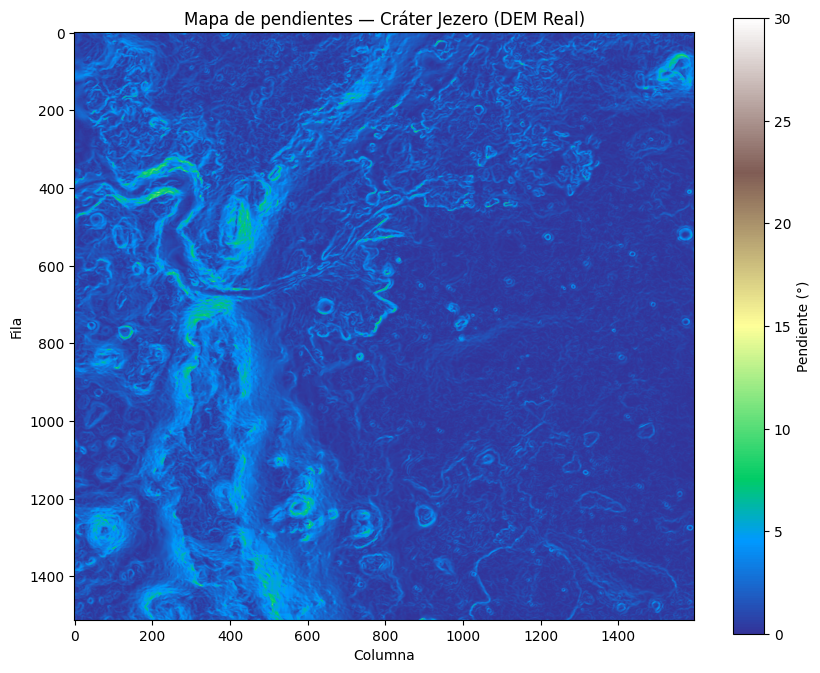

Figura guardada en: /content/slope_jezero.png
 GeoTIFF guardado en: /content/slope_jezero_output.tif

=== Estadísticas de pendiente ===
Media:   1.32°
Mediana: 0.88°
P90:     3.06°
% celdas > 20°: 0.0%


In [26]:
import matplotlib.pyplot as plt
import rasterio
import numpy as np

# --- Cálculo de la pendiente (Paso previo necesario) ---
# Factores de conversión para Jezero (~18° N) explicados en el Módulo 3
dx_m_per_deg = 56255.0
dy_m_per_deg = 59150.0

# Obtener espaciado de píxeles en metros usando la transformación afín
dx_metros = abs(transform.a) * dx_m_per_deg
dy_metros = abs(transform.e) * dy_m_per_deg

# Calcular el gradiente y la pendiente en grados
dzdy, dzdx = np.gradient(z, dy_metros, dx_metros)
slope_deg = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

# --- Figura ---
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(slope_deg, cmap="terrain", vmin=0, vmax=30)
cbar = fig.colorbar(im, ax=ax, label="Pendiente (°)")

# Título dinámico según si se cargó el DEM real o el sintético
tipo_dem = "DEM Real" if (DEM_REAL and os.path.exists(DEM_REAL)) else "DEM sintético"
ax.set_title(f"Mapa de pendientes — Cráter Jezero ({tipo_dem})")

ax.set_xlabel("Columna")
ax.set_ylabel("Fila")

png_path = "/content/slope_jezero.png"
plt.savefig(png_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {png_path}")

# --- GeoTIFF de pendiente ---
tif_path = "/content/slope_jezero_output.tif"
with rasterio.open(
    tif_path, "w", driver="GTiff",
    height=slope_deg.shape[0], width=slope_deg.shape[1],
    count=1, dtype="float32", crs=crs, transform=transform,
    nodata=-9999,
) as dst:
    dst.write(np.nan_to_num(slope_deg, nan=-9999).astype("float32"), 1)
print(f" GeoTIFF guardado en: {tif_path}")

# --- Estadísticas de pendiente (útil para documentar) ---
print("\n=== Estadísticas de pendiente ===")
print(f"Media:   {np.nanmean(slope_deg):.2f}°")
print(f"Mediana: {np.nanmedian(slope_deg):.2f}°")
print(f"P90:     {np.nanpercentile(slope_deg, 90):.2f}°")
print(f"% celdas > 20°: {100 * np.nanmean(slope_deg > 20):.1f}%")

✅ Heightmap: 1024×970
✅ Hillshade: 1024×970


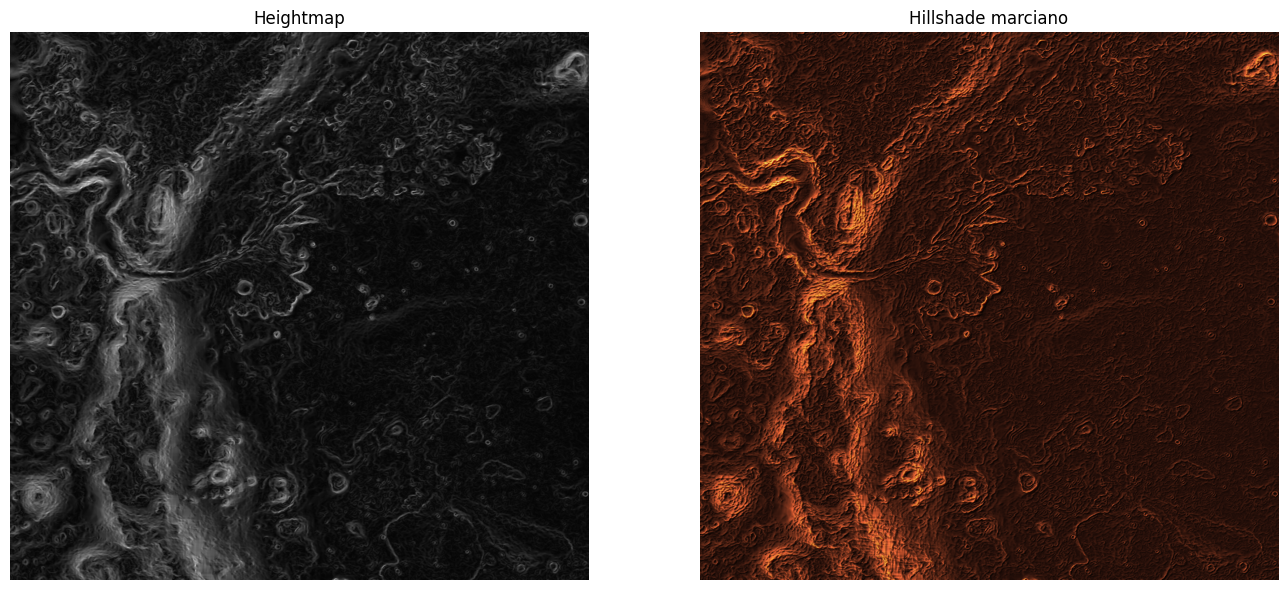

In [27]:
# ===== CELDA A: Generar heightmap + hillshade =====
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LightSource
import imageio.v3 as iio
from PIL import Image
import json

# --- Cargar DEM ---
with rasterio.open(dem_path) as src:
    z = src.read(1).astype(np.float64)
    if src.nodata is not None:
        z[z == src.nodata] = np.nan
    w, h = src.width, src.height
    crs = str(src.crs)

z_min, z_max = float(np.nanmin(z)), float(np.nanmax(z))
z_mean = float(np.nanmean(z))

# --- Downsample a 1024 px para un HTML liviano ---
TARGET = 1024
scale = TARGET / max(w, h) if max(w, h) > TARGET else 1.0
new_w, new_h = int(w * scale), int(h * scale)
z_filled = np.nan_to_num(z, nan=z_min)
z_resized = np.array(Image.fromarray(z_filled).resize((new_w, new_h), Image.LANCZOS))

# --- 1. Heightmap (8-bit grayscale) ---
z_norm = (z_resized - z_min) / (z_max - z_min)
iio.imwrite('/content/jezero_heightmap.png', (z_norm * 255).astype(np.uint8))
print(f"✅ Heightmap: {new_w}×{new_h}")

# --- 2. Hillshade con paleta marciana ---
ls = LightSource(azdeg=315, altdeg=45)
mars_colors = [
    (0.00, '#0f0604'), (0.20, '#3d1a0f'), (0.40, '#8b3a1f'),
    (0.60, '#c4651f'), (0.80, '#e8a855'), (1.00, '#f4e4b8'),
]
mars_cmap = LinearSegmentedColormap.from_list('mars', mars_colors)
hillshade = ls.shade(z_resized, cmap=mars_cmap, vert_exag=4, blend_mode='overlay')
iio.imwrite('/content/jezero_hillshade.png', (hillshade * 255).astype(np.uint8))
print(f"✅ Hillshade: {new_w}×{new_h}")

# --- 3. Metadata ---
meta = {
    'z_min': z_min, 'z_max': z_max, 'z_mean': z_mean,
    'width': new_w, 'height': new_h, 'crs': crs,
    'slope_mean': 1.32, 'slope_p90': 3.06,
}
with open('/content/jezero_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

# Preview rápida
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(z_resized, cmap='gray'); axes[0].set_title('Heightmap'); axes[0].axis('off')
axes[1].imshow(hillshade); axes[1].set_title('Hillshade marciano'); axes[1].axis('off')
plt.tight_layout(); plt.show()

DEM original: 1596 × 1512 px  (aspect = 1.0556)
Elevación min/max: 0.0 m / 13.2 m  (rango = 13.2 m)


/tmp/ipykernel_1121/515104596.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(z_uint8, mode="L").save(HEIGHTMAP_PNG)


Heightmap guardado: /content/jezero_heightmap.png
Longitud base64: 1,436,934 caracteres (~1403 KB)


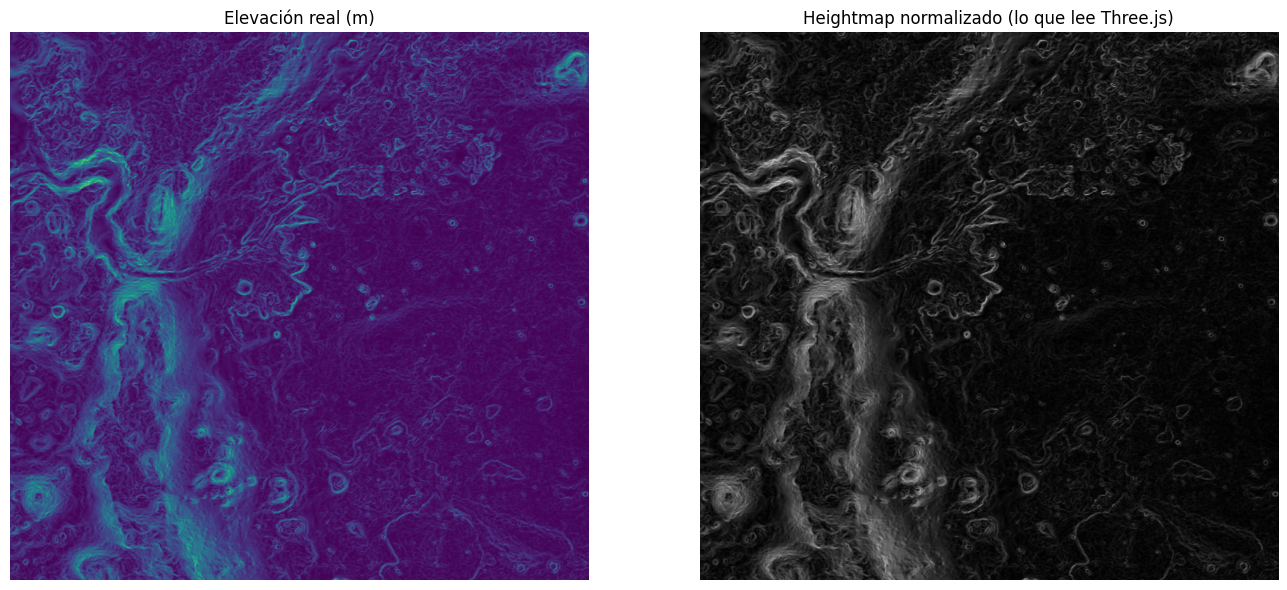

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Listo. Abre heightmap_base64.txt, copia todo su contenido
   y pégalo en la constante HM_URL de main.js


In [31]:
# ============================================================
# EXPORTAR HEIGHTMAP — DEM real de Jezero para Three.js
# Añadir esta celda al final del notebook, después de cargar `z` y `dem_path`
# ============================================================
import numpy as np
import rasterio
from PIL import Image
import base64, os
from google.colab import files

# --- 1. Leer DEM y limpiar nodata ---
with rasterio.open(dem_path) as src:
    z_full = src.read(1).astype(np.float32)
    nodata = src.nodata
    w_px, h_px = src.width, src.height

print(f"DEM original: {w_px} × {h_px} px  (aspect = {w_px/h_px:.4f})")

if nodata is not None:
    z_full = np.where(np.isclose(z_full, nodata), np.nan, z_full)

# --- 2. Rellenar NaNs con la mediana ---
if np.isnan(z_full).any():
    n_nan = np.isnan(z_full).sum()
    print(f"Rellenando {n_nan} píxeles nodata con la mediana…")
    z_full = np.where(np.isnan(z_full), np.nanmedian(z_full), z_full)

# --- 3. Normalizar 0..255 ---
z_min = float(z_full.min())
z_max = float(z_full.max())
print(f"Elevación min/max: {z_min:.1f} m / {z_max:.1f} m  (rango = {z_max-z_min:.1f} m)")

z_norm = (z_full - z_min) / (z_max - z_min)
z_uint8 = (z_norm * 255.0).round().astype(np.uint8)

# --- 4. Guardar PNG en gris ---
HEIGHTMAP_PNG = "/content/jezero_heightmap.png"
Image.fromarray(z_uint8, mode="L").save(HEIGHTMAP_PNG)
print(f"Heightmap guardado: {HEIGHTMAP_PNG}")

# --- 5. Base64 listo para pegar en main.js ---
with open(HEIGHTMAP_PNG, "rb") as f:
    b64 = base64.b64encode(f.read()).decode("ascii")
data_uri = f"data:image/png;base64,{b64}"

B64_PATH = "/content/heightmap_base64.txt"
with open(B64_PATH, "w") as f:
    f.write(data_uri)

print(f"Longitud base64: {len(data_uri):,} caracteres (~{len(data_uri)/1024:.0f} KB)")

# --- 6. Preview rápido ---
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(z_full, cmap="viridis")
axes[0].set_title("Elevación real (m)")
axes[0].axis("off")
axes[1].imshow(z_uint8, cmap="gray")
axes[1].set_title("Heightmap normalizado (lo que lee Three.js)")
axes[1].axis("off")
plt.tight_layout()
plt.savefig("/content/heightmap_preview.png", dpi=100, bbox_inches="tight")
plt.show()

# --- 7. Descargar ---
files.download(HEIGHTMAP_PNG)
files.download(B64_PATH)
files.download("/content/heightmap_preview.png")

print("\n✅ Listo. Abre heightmap_base64.txt, copia todo su contenido")
print("   y pégalo en la constante HM_URL de main.js")